# 05 — Business Impact

**Question for this notebook:** what would using the scorecard to approve or decline loans have meant in money terms, and how large is the expected-loss error caused by the calibration problem found in monitoring?

Evaluated on the 2015 loans, which no model has seen. LGD and EAD are estimated on development loans only.

In [1]:
%load_ext autoreload
%autoreload 2

import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
from src import impact
from src.data_prep import load_model_data
from src.features import add_derived_features

pd.set_option("display.max_columns", 30)
TARGET = config.TARGET

data = impact.add_loss_fields(add_derived_features(load_model_data()), TARGET)
development = data[data["sample"] == "development"]
monitoring = data[data["sample"] == "monitoring"].copy()

with open(config.ROOT / "models" / "champion_scorecard.pkl", "rb") as f:
    card = pickle.load(f)
with open(config.ROOT / "models" / "challengers.pkl", "rb") as f:
    challenger = pickle.load(f)["LightGBM, all candidates"]
with open(config.ROOT / "models" / "validation_artifacts.pkl", "rb") as f:
    shift = pickle.load(f)["intercept_shift_2014"]

pds = {
    "champion": card.predict_pd(monitoring),
    "champion recalibrated": expit(card.log_odds_bad(monitoring) + shift),
    "challenger (LightGBM, all features)": challenger.predict_pd(monitoring),
}

(CVXPY) Nov 23 10:39:23 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/home/sava/project/.venv/lib/python3.12/site-packages/highspy/_core.cpython-312-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


## 1. LGD and EAD from development data
Outcome fields (`total_rec_prncp`, `recoveries`, collection fees) are used here only to measure what was actually lost — never as PD inputs.
- **EAD at default** = funded amount − principal repaid before default.
- **Loss** = EAD − (recoveries − collection fees).
- **LGD** = total loss / total EAD over defaulted loans; **EAD factor** = total EAD / total funded amount of defaulted loans.

Using the funded amount as EAD would overstate exposure, because borrowers repay part of the principal before defaulting.

In [2]:
lgd_ead = impact.lgd_and_ead_factor(development, TARGET)
check_2015 = impact.lgd_and_ead_factor(monitoring, TARGET)
pd.DataFrame({"development (used)": lgd_ead, "2015 (check only)": check_2015}).round(4)

,development (used),2015 (check only)
defaults,14327.0000,42150.0000
lgd,0.8869,0.8928
ead_factor,0.5731,0.5844


## 2. Expected loss vs realised loss for the 2015 portfolio
$EL_i = PD_i \times LGD \times (\text{EAD factor} \times \text{funded amount}_i)$

In [3]:
funded = monitoring["funded_amnt"].to_numpy()
expected_loss = {name: p * lgd_ead["lgd"] * lgd_ead["ead_factor"] * funded for name, p in pds.items()}
realised = monitoring["realised_loss"].sum()

el_table = pd.DataFrame({
    name: {
        "expected_loss_musd": el.sum() / 1e6,
        "realised_loss_musd": realised / 1e6,
        "expected_loss_rate_pct": 100 * el.sum() / funded.sum(),
        "realised_loss_rate_pct": 100 * realised / funded.sum(),
        "shortfall_musd": (realised - el.sum()) / 1e6,
        "shortfall_pct_of_expected": 100 * (realised / el.sum() - 1),
    }
    for name, el in expected_loss.items()
}).T
print(f"2015 portfolio: {len(monitoring):,} loans, funded ${funded.sum() / 1e9:.2f}bn")
el_table.round(2)

2015 portfolio: 282,848 loans, funded $3.62bn


,expected_loss_musd,realised_loss_musd,expected_loss_rate_pct,realised_loss_rate_pct,shortfall_musd,shortfall_pct_of_expected
champion,221.02,273.8,6.10,7.56,52.79,23.88
champion recalibrated,233.39,273.8,6.44,7.56,40.41,17.32
"challenger (LightGBM, all features)",232.16,273.8,6.41,7.56,41.64,17.94


## 3. Cutoff analysis: what if we approved only the lowest-risk X%?
Loans are ranked by each model's risk; the lowest-risk share is approved. Ranking is identical for the original and recalibrated champion. LC's `int_rate` is the benchmark ranking (LC's own pricing). Net return = cash received over the loan's life (principal, interest, fees, recoveries) / funded amount − 1, before funding and servicing costs.

In [4]:
approval_rates = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 1.0]
rankings = {
    "champion": (pds["champion"], expected_loss["champion"]),
    "challenger (LightGBM, all features)": (pds["challenger (LightGBM, all features)"], expected_loss["challenger (LightGBM, all features)"]),
    "LC int_rate (benchmark)": (monitoring["int_rate"].to_numpy(), None),
}
cutoffs = {
    name: impact.cutoff_table(monitoring, risk, TARGET, approval_rates, el)
    for name, (risk, el) in rankings.items()
}
cutoffs["champion"].round(2)

,approved_loans,bad_rate_pct,bads_avoided_pct,goods_rejected_pct,realised_loss_rate_pct,net_return_pct,expected_loss_rate_pct
approval_rate_pct,,,,,,,
50.0,141424,8.75,70.65,46.38,4.37,7.56,3.60
60.0,169709,9.82,60.44,36.42,4.91,7.43,4.01
70.0,197994,10.89,48.85,26.70,5.47,7.26,4.43
80.0,226278,12.05,35.34,17.31,6.06,7.03,4.88
85.0,240421,12.64,27.88,12.74,6.38,6.90,5.12
90.0,254563,13.30,19.69,8.30,6.71,6.77,5.39
95.0,268706,14.00,10.73,4.00,7.09,6.59,5.70
100.0,282848,14.90,0.00,0.00,7.56,6.35,6.10


In [5]:
pd.concat({name: t[["bad_rate_pct", "realised_loss_rate_pct", "net_return_pct"]] for name, t in cutoffs.items()}, axis=1).round(2)

champion                                        \
                  bad_rate_pct realised_loss_rate_pct net_return_pct   
approval_rate_pct                                                      
50.0                      8.75                   4.37           7.56   
60.0                      9.82                   4.91           7.43   
70.0                     10.89                   5.47           7.26   
80.0                     12.05                   6.06           7.03   
85.0                     12.64                   6.38           6.90   
90.0                     13.30                   6.71           6.77   
95.0                     14.00                   7.09           6.59   
100.0                    14.90                   7.56           6.35   

                  challenger (LightGBM, all features)                         \
                                         bad_rate_pct realised_loss_rate_pct   
approval_rate_pct                                                              
50.0                                             8.24                   3.92   
60.0                                             9.34                   4.47   
70.0                                            10.47                   5.05   
80.0                                            11.65                   5.69   
85.0                                            12.33                   6.05   
90.0                                            13.05                   6.45   
95.0                                            13.86                   6.92   
100.0                                           14.90                   7.56   

                                 LC int_rate (benchmark)  \
                  net_return_pct            bad_rate_pct   
approval_rate_pct                                          
50.0                        7.79                    8.28   
60.0                        7.67                    9.53   
70.0                        7.52                   10.66   
80.0                        7.30                   11.90   
85.0                        7.15                   12.53   
90.0                        6.97                   13.18   
95.0                        6.73                   13.93   
100.0                       6.35                   14.90   

                                                         
                  realised_loss_rate_pct net_return_pct  
approval_rate_pct                                        
50.0                                3.68           7.05  
60.0                                4.33           7.01  
70.0                                4.94           6.98  
80.0                                5.63           6.88  
85.0                                5.99           6.82  
90.0                                6.40           6.74  
95.0                                6.89           6.60  
100.0                               7.56           6.35

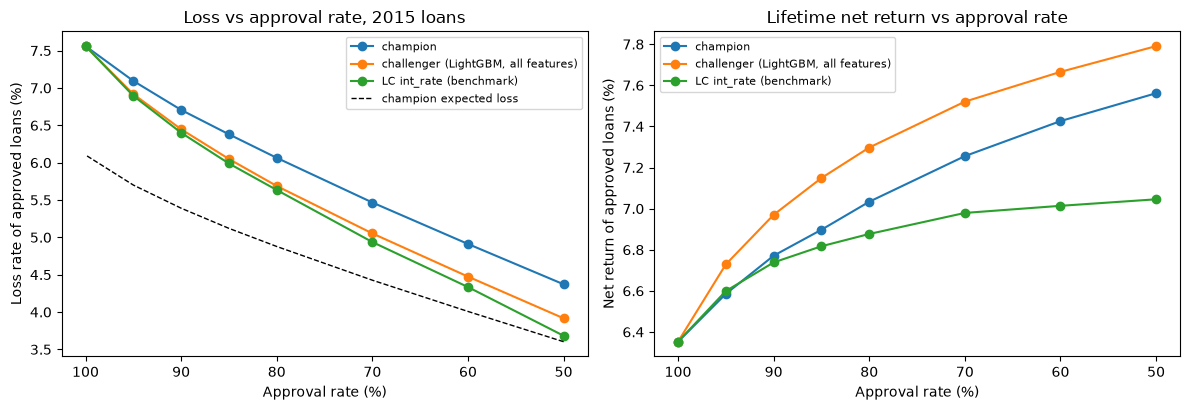

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name, t in cutoffs.items():
    axes[0].plot(t.index, t["realised_loss_rate_pct"], "o-", label=name)
    axes[1].plot(t.index, t["net_return_pct"], "o-", label=name)
axes[0].plot(cutoffs["champion"].index, cutoffs["champion"]["expected_loss_rate_pct"], "k--", lw=1, label="champion expected loss")
axes[0].set(xlabel="Approval rate (%)", ylabel="Loss rate of approved loans (%)", title="Loss vs approval rate, 2015 loans")
axes[1].set(xlabel="Approval rate (%)", ylabel="Net return of approved loans (%)", title="Lifetime net return vs approval rate")
for ax in axes:
    ax.legend(fontsize=8)
    ax.invert_xaxis()
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "05_approval_vs_loss.png", dpi=150)

## 4. Swap set at 85% approval: where do champion and challenger disagree?

In [7]:
def approved_mask(risk: np.ndarray, rate: float) -> np.ndarray:
    mask = np.zeros(len(risk), dtype=bool)
    mask[np.argsort(risk, kind="stable")[: int(round(rate * len(risk)))]] = True
    return mask

a_champ = approved_mask(pds["champion"], 0.85)
a_chall = approved_mask(pds["challenger (LightGBM, all features)"], 0.85)
groups = {
    "both approve": a_champ & a_chall,
    "only champion approves": a_champ & ~a_chall,
    "only challenger approves": ~a_champ & a_chall,
    "both decline": ~a_champ & ~a_chall,
}
swap = pd.DataFrame({
    name: {
        "loans": m.sum(),
        "bad_rate_pct": 100 * monitoring.loc[m, TARGET].mean(),
        "loss_rate_pct": 100 * monitoring.loc[m, "realised_loss"].sum() / monitoring.loc[m, "funded_amnt"].sum(),
    }
    for name, m in groups.items()
}).T
swap.round(2)

,loans,bad_rate_pct,loss_rate_pct
both approve,225213.0,11.70,5.76
only champion approves,15208.0,26.54,15.41
only challenger approves,15208.0,21.65,11.60
both decline,27219.0,31.08,17.76


In [8]:
el_table.to_csv(config.REPORTS_DIR / "impact_expected_vs_realised_loss_2015.csv")
pd.concat(cutoffs, names=["model"]).to_csv(config.REPORTS_DIR / "impact_cutoffs_2015.csv")
swap.to_csv(config.REPORTS_DIR / "impact_swap_set_2015.csv")

## 5. Findings

1. **LGD and EAD.** On defaulted development loans, 57% of the funded principal is still outstanding at default (EAD factor 0.57) and 89% of that is lost (LGD 0.89 — typical for unsecured consumer loans with little recovery). Both are stable in 2015 (0.58 and 0.89). Treating the full funded amount as exposure would have overstated EAD by about 43%.
2. **The calibration problem has a price.** For the 2015 portfolio ($3.62bn funded, 282,848 loans) the champion's expected loss is $221M (6.10%) against a realised loss of $274M (7.56%): a **$53M (24%) shortfall**. The 2014 recalibration reduces it to $40M (17%); the challenger's shortfall is similar ($42M). The loss gap is larger than the PD gap (≈15%) because the defaulted loans are slightly larger and repay a little less before default than in development.
3. **Using the scorecard to decline the riskiest loans pays off.** Approving the lowest-risk 85% (declining 15%) would have cut the bad rate from 14.9% to 12.6% and the loss rate from 7.6% to 6.4%, avoiding 28% of defaults while declining 13% of good borrowers. Lifetime net return on the approved loans rises from 6.35% to 6.90%: the extra interest charged on the riskiest loans did not compensate for their losses.
4. **Challenger vs champion in money terms.** At 85% approval the challenger lowers the loss rate further (6.05% vs 6.38%) and raises net return by about 0.25 percentage points (7.15% vs 6.90%). The swap set shows why: of the 15,208 loans each model would approve and the other would decline, the champion-only loans have a 26.5% bad rate and 15.4% loss rate, the challenger-only loans 21.7% and 11.6%.
5. **Minimising losses is not the same as maximising return.** Ranking by LC's interest rate gives the lowest loss rate at most cutoffs, but the lowest net return, because it declines exactly the highest-yielding loans. A cutoff should be set on risk-adjusted return, not on default rate alone.
6. **Caveats.** Net return is before funding, servicing and capital costs, and ignores that declined applicants might have gone elsewhere or been offered a smaller loan; the analysis uses only accepted loans, so the effect on applicants LC itself rejected is unknown (no reject inference).

**Business recommendation.** (a) Do not use the uncorrected PD for loss provisioning: it understated 2015 losses by about a quarter. (b) If the scorecard is used for decisions, a cutoff around 85–90% approval improves risk-adjusted return. (c) The challenger's extra ≈0.25 pp of return is a concrete, quantified argument for the redevelopment recommended in notebooks 03 and 04.